# 03 - Debate experiments (Specifications 4-8)

Protocol: round 0 = three independent justified answers (identical to notebook 02's samples 0-2).
Rounds 1-2 are **synchronous**: every agent gets its own previous response plus the other agents' previous responses
(anonymous, same snapshot) and must name one specific strength or weakness before revising.

* `free`: unrestricted discussion. `structured`: PROPOSED ANSWER / SUPPORTING ARGUMENT / CRITICISM OF ALTERNATIVE / FINAL ANSWER.
  Same word limit and `max_tokens` for both free and structured.
* Final decision: majority vote vs. an LLM judge that sees the anonymised, shuffled final arguments and never the gold answer.
* Everything is compared with independent voting and with budget-matched baselines (self-revision, more independent samples).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loader, metrics, prompts
config.ensure_dirs()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SPLIT = "test"   #"dev" for development (100 questions from validation split); "test" for the testing (300 questions from test split)
print("model:", config.MODEL, "| server:", config.BASE_URL)

model: llama3.1:8b | server: http://localhost:11434/v1


In [2]:
from src.debate_engine import (run_dataset, run_debate, transcript_path, load_records, render_transcript)
from src.llm_client import LLMClient

client = LLMClient()
questions = data_loader.load_sampled(SPLIT)
qids = [q.id for q in questions]
cfg = config.DebateConfig()         
print(cfg)

by_qid = lambda recs: {r["qid"]: r for r in recs}
single_direct = by_qid(load_records(transcript_path(SPLIT, "single_direct")))
single_just = by_qid(load_records(transcript_path(SPLIT, "single_justify")))
ind = by_qid(load_records(transcript_path(SPLIT, "independent_justify")))
assert ind, "run notebook 02 first"

DebateConfig(n_agents=3, max_rounds=2, protocol='structured', early_stop=False, judge_final=True, judge_round0=True)


### Specification 4 & 5 - run debate (free vs structured)

In [3]:
debate = {}
for protocol in ("free", "structured"):
    recs = run_dataset(
        lambda q, p=protocol: run_debate(client, q, p, n_agents=cfg.n_agents, rounds=cfg.max_rounds,
                                         early_stop=cfg.early_stop, judge_final=cfg.judge_final,
                                         judge_round0=cfg.judge_round0),
        questions, transcript_path(SPLIT, f"debate_{protocol}"))
    debate[protocol] = by_qid(recs)
print(client.stats)

# paired design check: round 0 must be exactly the independent samples
for p in debate:
    assert all(debate[p][i]["answers_by_round"][0] == ind[i]["answers"][:cfg.n_agents] for i in qids)
print("round 0 of both protocols == independent samples 0-2")

test_debate_free: 0it [00:00, ?it/s]

test_debate_structured: 0it [00:00, ?it/s]

{'calls': 0, 'cached_calls': 0, 'input_tokens': 0, 'output_tokens': 0}
round 0 of both protocols == independent samples 0-2


In [4]:
# readable transcript of one question where agents initially disagreed
ex = next((debate["structured"][i] for i in qids if not metrics.is_unanimous(debate["structured"][i]["answers_by_round"][0])), debate["structured"][qids[0]])
print(render_transcript(ex)[:3500])

# CSZ20754  (gold: B, mode: debate_structured)

## round 0 · agent · agent 0 → answer B  (111+78 tok, 1.80s)

Velocity is a vector quantity that has both magnitude (speed) and direction. If an object's velocity is constant, its speed and direction remain the same. However, its position can change, as can its direction, without affecting its velocity. Acceleration, on the other hand, is a change in velocity over time, so if acceleration changes, velocity must also change.

Answer: B

## round 0 · agent · agent 1 → answer C  (111+103 tok, 7.90s)

When considering the characteristics of motion, velocity is a vector quantity that depends on both speed and direction. Acceleration, on the other hand, is a measure of how quickly the velocity of an object is changing. If an object's speed changes, its velocity will also change, as velocity is directly dependent on speed. However, an object's direction can change without affecting its speed, thus not changing its velocity. This is evident in sc

### Round-by-round analysis

--- free ---
 round  majority_acc  mean_agent_acc  pairwise_disagreement  unanimous_rate  unanimous_wrong_rate  unanimous_correct_rate  unparsed_rate
     0         0.830           0.823                  0.123           0.823                 0.070                   0.753          0.000
     1         0.817           0.791                  0.169           0.757                 0.073                   0.683          0.017
     2         0.797           0.760                  0.223           0.683                 0.067                   0.617          0.026
--- structured ---
 round  majority_acc  mean_agent_acc  pairwise_disagreement  unanimous_rate  unanimous_wrong_rate  unanimous_correct_rate  unparsed_rate
     0         0.830           0.823                  0.123           0.823                  0.07                   0.753            0.0
     1         0.837           0.828                  0.120           0.830                  0.07                   0.760            0.0
     2   

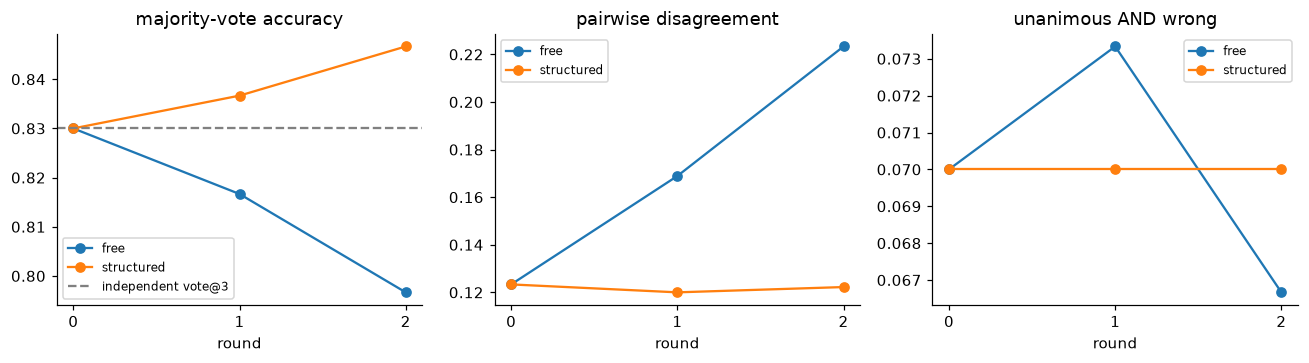

In [5]:
rs = {p: pd.DataFrame(metrics.round_summary([debate[p][i] for i in qids])) for p in debate}
for p, t in rs.items():
    print(f"--- {p} ---"); print(t.round(3).to_string(index=False))
    t.round(4).to_csv(config.TABLES_DIR / f"{SPLIT}_rounds_{p}.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for p, t in rs.items():
    ax[0].plot(t["round"], t["majority_acc"], marker="o", label=p)
    ax[1].plot(t["round"], t["pairwise_disagreement"], marker="o", label=p)
    ax[2].plot(t["round"], t["unanimous_wrong_rate"], marker="o", label=p)
ind_acc = np.mean([metrics.is_correct(metrics.vote_at_k(ind[i], 3)["answer"], ind[i]["gold"]) for i in qids])
ax[0].axhline(ind_acc, ls="--", c="gray", label="independent vote@3")
for a, t in zip(ax, ["majority-vote accuracy", "pairwise disagreement", "unanimous AND wrong"]):
    a.set(xlabel="round", title=t, xticks=range(cfg.max_rounds + 1)); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(config.PLOTS_DIR / f"03_{SPLIT}_rounds.png"); plt.show()

### Comparism between free(unrestricted) vs structured: accuracy, length, format compliance

In [6]:
def final_correct(p, decide="majority"):
    out = []
    for i in qids:
        r = debate[p][i]
        ans = metrics.majority_vote(metrics.padded_trajectory(r)[-1], i)["answer"] if decide == "majority" else r["judge_final"]["answer"]
        out.append(metrics.is_correct(ans, r["gold"]))
    return np.array(out)

print("structured vs free (majority after debate):", metrics.mcnemar_exact(final_correct("free"), final_correct("structured")))

len_rows = []
for p in debate:
    for rnd in range(0, cfg.max_rounds + 1):
        calls = [c for i in qids for c in debate[p][i]["calls"] if c["role"] == "agent" and c["round"] == rnd]
        words = [len(c["text"].split()) for c in calls]
        row = {"protocol": p, "round": rnd, "mean_output_tokens": np.mean([c["output_tokens"] for c in calls]),
               "mean_words": np.mean(words), "max_words": max(words),
               "truncated": np.mean([c["stop_reason"] == "max_tokens" for c in calls]),
               "unparsed": np.mean([c["answer"] is None for c in calls]),
               "max_input_tokens": max(c["input_tokens"] for c in calls)}
        if p == "structured" and rnd > 0:
            row["all_4_fields"] = np.mean([len(metrics.parse_structured(c["text"])) == 4 for c in calls])
        len_rows.append(row)
pd.DataFrame(len_rows).round(3)

structured vs free (majority after debate): {'a_only': 5, 'b_only': 20, 'delta_acc_b_minus_a': 0.050000000000000044, 'p_value': 0.004077315330505371}


,protocol,round,mean_output_tokens,mean_words,max_words,truncated,unparsed,max_input_tokens,all_4_fields
0,free,0,92.784,76.193,237,0.000,0.000,229,NaN
1,free,1,119.249,96.084,291,0.001,0.017,764,NaN
2,free,2,112.071,90.099,302,0.002,0.026,803,NaN
3,structured,0,92.784,76.193,237,0.000,0.000,229,NaN
4,structured,1,121.791,89.500,195,0.000,0.000,806,1.0
5,structured,2,115.321,84.862,136,0.000,0.000,766,1.0


### Specification 6 - final decision methods

Compared on the *same* final-round arguments: plurality vote (hash tie-break) vs. LLM judge.
`judge on round 0` is the control from the baseline

In [7]:
for p in debate:
    d = metrics.decision_comparison([debate[p][i] for i in qids])
    rows = d.pop("rows")
    print(f"--- {p}: vote vs judge on final-round arguments ---")
    print(pd.Series(d).to_string())
    print("paired test judge vs majority:", metrics.mcnemar_exact(final_correct(p, "majority"), final_correct(p, "judge")))
    j0 = np.array([metrics.is_correct(debate[p][i]["judge_round0"]["answer"], debate[p][i]["gold"]) for i in qids])
    v0 = np.array([metrics.is_correct(metrics.vote_at_k(ind[i], 3)["answer"], ind[i]["gold"]) for i in qids])
    print(f"judge on round-0 (no debate) accuracy {j0.mean():.3f} vs independent vote@3 {v0.mean():.3f}; outcome differs on "
          f"{np.mean([debate[p][i]['judge_round0']['answer'] != metrics.vote_at_k(ind[i], 3)['answer'] for i in qids]):.1%} of questions\n")
    pd.DataFrame(rows).to_csv(config.TABLES_DIR / f"{SPLIT}_decision_{p}.csv", index=False)

--- free: vote vs judge on final-round arguments ---
n                        300.000000
majority_acc               0.796667
judge_acc                  0.746667
outcome_changed           47.000000
outcome_changed_rate       0.156667
judge_fixes_majority      11.000000
judge_breaks_majority     26.000000
both_wrong_but_differ     10.000000
paired test judge vs majority: {'a_only': 26, 'b_only': 11, 'delta_acc_b_minus_a': -0.04999999999999993, 'p_value': 0.020073851919732988}
judge on round-0 (no debate) accuracy 0.837 vs independent vote@3 0.830; outcome differs on 7.7% of questions

--- structured: vote vs judge on final-round arguments ---
n                        300.000000
majority_acc               0.846667
judge_acc                  0.826667
outcome_changed           18.000000
outcome_changed_rate       0.060000
judge_fixes_majority       4.000000
judge_breaks_majority     10.000000
both_wrong_but_differ      4.000000
paired test judge vs majority: {'a_only': 10, 'b_only': 4, 'del

### Specification 7 - Answer-change analysis

Every rate is printed as `numerator/denominator`. 

In [8]:
def show_changes(rows):
    t = pd.DataFrame(rows)
    t["value"] = [f"{n}/{d} ({r:.1%})" if d else f"{n}/{d} (n/a)" for n, d, r in zip(t.num, t.den, t.rate)]
    return t[["metric", "value", "denominator"]]

changes = {}
for p in debate:
    recs = [debate[p][i] for i in qids]
    changes[p] = metrics.answer_change_rows(recs, 0, -1)
    pd.DataFrame(changes[p]).to_csv(config.TABLES_DIR / f"{SPLIT}_changes_{p}_overall.csv", index=False)
    print(f"--- {p}: round 0 -> final ---")
    print(show_changes(changes[p]).to_string(index=False))

--- free: round 0 -> final ---
                                                   metric           value                                       denominator
                               Agent correct -> incorrect  90/741 (12.1%)                        of agents correct at start
                               Agent incorrect -> correct  33/159 (20.8%)                      of agents incorrect at start
                                     Agent changed answer 150/900 (16.7%)                                     of all agents
                       Majority vote correct -> incorrect   18/249 (7.2%)           of questions with correct vote at start
                       Majority vote incorrect -> correct    8/51 (15.7%)         of questions with incorrect vote at start
               Correct minority: group vote correct after    5/16 (31.2%)              of questions with a correct minority
                Correct minority: unanimous correct after     0/16 (0.0%)              of questions w

In [9]:
for p in debate:
    for r, rows in metrics.per_round_answer_changes([debate[p][i] for i in qids]).items():
        print(f"--- {p}: round {r-1} -> {r} ---")
        print(show_changes(rows).head(6).to_string(index=False))
        pd.DataFrame(rows).to_csv(config.TABLES_DIR / f"{SPLIT}_changes_{p}_r{r}.csv", index=False)

--- free: round 0 -> 1 ---
                                    metric         value                               denominator
                Agent correct -> incorrect 41/741 (5.5%)                of agents correct at start
                Agent incorrect -> correct 12/159 (7.5%)              of agents incorrect at start
                      Agent changed answer 70/900 (7.8%)                             of all agents
        Majority vote correct -> incorrect  7/249 (2.8%)   of questions with correct vote at start
        Majority vote incorrect -> correct   3/51 (5.9%) of questions with incorrect vote at start
Correct minority: group vote correct after  2/16 (12.5%)      of questions with a correct minority
--- free: round 1 -> 2 ---
                                    metric           value                               denominator
                Agent correct -> incorrect   62/712 (8.7%)                of agents correct at start
                Agent incorrect -> correct  34/188 

### Specification 8 - Quality-cost comparison


In [10]:
selfrev = by_qid(load_records(transcript_path(SPLIT, "selfrevise")))
if not selfrev:
    from src.debate_engine import run_self_revision
    selfrev = by_qid(run_dataset(lambda q: run_self_revision(client, q, cfg.max_rounds), questions, transcript_path(SPLIT, "selfrevise")))

methods = {}  
def add(name, fn):
    methods[name] = [fn(i) for i in qids]

def pq(correct, us, dis=np.nan, ans_changed=np.nan):
    return {"correct": bool(correct), "tokens": us["total_tokens"], "lat_sum": us["latency_sum_s"], "lat_crit": us["latency_critical_s"], "dis": dis, "ans_changed": ans_changed}

ok = metrics.is_correct
add("single direct", lambda i: pq(ok(single_direct[i]["answer"], single_direct[i]["gold"]), metrics.usage(single_direct[i]["calls"])))
add("single justified", lambda i: pq(ok(single_just[i]["answer"], single_just[i]["gold"]), metrics.usage(single_just[i]["calls"])))
add("independent vote@3", lambda i: pq(ok(metrics.vote_at_k(ind[i], 3)["answer"], ind[i]["gold"]), metrics.usage(ind[i]["calls"], agents=range(3)),
                                       metrics.pairwise_disagreement(ind[i]["answers"][:3])))
d0 = debate["structured"]
add("independent x3 + judge", lambda i: pq(ok(d0[i]["judge_round0"]["answer"], d0[i]["gold"]),
                                           metrics.usage(d0[i]["calls"], rounds=[0], roles=["agent", "judge_round0"]),
                                           metrics.pairwise_disagreement(d0[i]["answers_by_round"][0])))
add("self-revision (2 rounds)", lambda i: pq(ok(selfrev[i]["answers_by_round"][-1][0], selfrev[i]["gold"]), metrics.usage(selfrev[i]["calls"]), ans_changed=float(selfrev[i]["answers_by_round"][-1][0] != selfrev[i]["answers_by_round"][0][0])))

for p in debate:
    D = debate[p]
    fin = lambda i, D=D: metrics.padded_trajectory(D[i])[-1]
    def change_rate(i, D=D, fin=fin):
        r0 = D[i]["answers_by_round"][0]
        rf = fin(i)
        return np.mean([a != b for a, b in zip(r0, rf)])
    
    add(f"debate-{p} + majority", lambda i, D=D, fin=fin: pq(ok(metrics.majority_vote(fin(i), i)["answer"], D[i]["gold"]),
                                                       metrics.usage(D[i]["calls"], roles=["agent"]), metrics.pairwise_disagreement(fin(i)), ans_changed=change_rate(i)))
    add(f"debate-{p} + judge", lambda i, D=D, fin=fin: pq(ok(D[i]["judge_final"]["answer"], D[i]["gold"]),
                                                     metrics.usage(D[i]["calls"], roles=["agent", "judge_final"]), metrics.pairwise_disagreement(fin(i)), ans_changed=change_rate(i)))
   
    # more independent samples under the same per-question token budget as the debate (agents only);
    
    def matched(i, D=D):
        budget = metrics.usage(D[i]["calls"], roles=["agent"])["total_tokens"]
        k = metrics.k_for_budget(ind[i], budget)
        return pq(ok(metrics.vote_at_k(ind[i], k)["answer"], ind[i]["gold"]), metrics.usage(ind[i]["calls"], agents=range(k)),
                  metrics.pairwise_disagreement(ind[i]["answers"][:k]))
    add(f"independent vote, debate-{p} token budget (max {config.MAX_INDEP_SAMPLES} samples)", matched)

vote3 = np.array([m["correct"] for m in methods["independent vote@3"]])
rows = []
for name, ms in methods.items():
    c = np.array([m["correct"] for m in ms]); mean, lo, hi = metrics.bootstrap_ci(c)
    t = metrics.mcnemar_exact(vote3, c)
    rows.append({"method": name, "accuracy": mean,
                 "disagreement": np.nanmean([m["dis"] for m in ms]) if not np.all(np.isnan([m["dis"] for m in ms])) else np.nan,
                 "answer_change_rate": np.nanmean([m["ans_changed"] for m in ms]) if not np.all(np.isnan([m["ans_changed"] for m in ms])) else np.nan,
                 "tokens/q": np.mean([m["tokens"] for m in ms]),
                 "latency": np.mean([m["lat_crit"] for m in ms])})
results = pd.DataFrame(rows).round(4)
results.to_csv(config.TABLES_DIR / f"{SPLIT}_comparison.csv", index=False)
results

,method,accuracy,disagreement,answer_change_rate,tokens/q,latency
0,single direct,0.8033,NaN,NaN,131.6200,0.2846
1,single justified,0.8267,NaN,NaN,232.3000,4.0906
2,independent vote@3,0.8300,0.1233,NaN,694.2133,8.0553
3,independent x3 + judge,0.8367,0.1233,NaN,1275.0567,12.8706
4,self-revision (2 rounds),0.6200,NaN,0.3633,978.6133,14.6153
5,debate-free + majority,0.7967,0.2233,0.1667,4409.7433,29.0957
6,debate-free + judge,0.7467,0.2233,0.1667,5042.6667,33.3715
7,"independent vote, debate-free token budget (max 9 samples)",0.8533,0.1329,NaN,2087.9900,8.9293
8,debate-structured + majority,0.8467,0.1222,0.0111,4702.2100,29.7988
9,debate-structured + judge,0.8267,0.1222,0.0111,5352.7467,34.6365


#### Manual inspection

In [11]:
kinds = ("useful_criticism", "unsupported_persuasion", "repeated_argument")
for p in debate:
    recs = [debate[p][i] for i in qids]
    examples = []
    for kind in kinds:
        ex = metrics.find_examples(recs, kind, k=8, seed=config.SEED)
        print(f"{p:10s} {kind:24s} candidates: {len(ex)}")
        examples += ex
    table = pd.DataFrame(examples).assign(label="", notes="")
    table.to_csv(config.TABLES_DIR / f"{SPLIT}_inspection_{p}.csv", index=False)
print("\nSaved results/tables/*_inspection_*.csv - open in Excel, read previous_text / new_text, fill in the label column.")


t = pd.read_csv(config.TABLES_DIR / f"{SPLIT}_inspection_structured.csv").fillna("")
for kind in kinds:
    row = t[t.kind == kind].head(1)
    if row.empty: continue
    r = row.iloc[0]
    print(f"\n===== {kind}: {r.qid} agent {r.agent} round {r['round']} | gold {r.gold} | {r.answers_before} -> {r.answers_after}")
    print("PREVIOUS:", r.previous_text[:500]); print("NEW:", r.new_text[:500])

free       useful_criticism         candidates: 8
free       unsupported_persuasion   candidates: 8
free       repeated_argument        candidates: 8
structured useful_criticism         candidates: 7
structured unsupported_persuasion   candidates: 0
structured repeated_argument        candidates: 8

Saved results/tables/*_inspection_*.csv - open in Excel, read previous_text / new_text, fill in the label column.

===== useful_criticism: Mercury_SC_407400 agent 0 round 1 | gold C | ['D', 'C', 'D'] -> ['C', 'C', 'D']
PREVIOUS: Before starting an investigation, it's essential to plan and organize the steps involved. This ensures that the investigation is conducted in a systematic and controlled manner. Making daily observations of the light bulbs (option D) would be a crucial step, but it should not come first. The initial step is to plan and prepare for the investigation.

Answer: D
NEW: PROPOSED ANSWER: C
SUPPORTING ARGUMENT: Making a table for recording data is a crucial step in plannin

In [13]:
# after labelling: counts per kind x label
import glob
frames = [pd.read_csv(f).assign(protocol=f.split("_")[-1][:-4]) for f in glob.glob(str(config.TABLES_DIR / f"{SPLIT}_inspection_*.csv"))]
lab = pd.concat(frames, ignore_index=True).fillna("") if frames else pd.DataFrame()
lab = lab[lab.label != ""] if not lab.empty else lab
print(pd.crosstab([lab.protocol, lab.kind], lab.label) if not lab.empty else "no labels filled in yet")

label                              no-changes  peer-pressure  specific-and-correct  specific-but-wrong
protocol   kind                                                                                       
free       repeated_argument                8              0                     0                   0
           unsupported_persuasion           0              2                     0                   6
           useful_criticism                 0              0                     8                   0
structured repeated_argument                8              0                     0                   0
           useful_criticism                 0              2                     5                   0
